Analyze and visualize feature importance in tree-based models (Random Forest, XGBoost, LightGBM) using impurity-based metrics, permutation importance, and SHAP values to guide feature engineering and selection.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score

In [3]:
try:
    import xgboost as xgb
    HAS_XGB = True
except ImportError:
    HAS_XGB = False

try:
    import lightgbm as lgb
    HAS_LGB = True
except ImportError:
    HAS_LGB = False

In [4]:
np.random.seed(42)
n_samples = 1200
n_features = 10

In [5]:
X_raw, y_raw = make_classification(
    n_samples=n_samples,
    n_features=n_features,
    n_informative=6,
    n_redundant=2,
    n_repeated=0,
    n_classes=2,
    weights=[0.65, 0.35],
    random_state=42
)

In [6]:
feature_cols = [f"clinical_biomarker_{i+1}" for i in range(n_features)]
df_clinical = pd.DataFrame(X_raw, columns=feature_cols)
y = y_raw

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    df_clinical, y, test_size=0.25, random_state=42, stratify=y
)

In [9]:
rf_model = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42)
rf_model.fit(X_train, y_train)

RandomForestClassifier(max_depth=8, random_state=42)

In [10]:
if HAS_XGB:
    xgb_model = xgb.XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.05, random_state=42, eval_metric='logloss')
    xgb_model.fit(X_train, y_train)
else:
    from sklearn.ensemble import HistGradientBoostingClassifier
    xgb_model = HistGradientBoostingClassifier(max_iter=100, random_state=42)
    xgb_model.fit(X_train, y_train)

In [11]:
if HAS_LGB:
    lgb_model = lgb.LGBMClassifier(n_estimators=100, max_depth=5, learning_rate=0.05, random_state=42, verbose=-1)
    lgb_model.fit(X_train, y_train)
else:
    from sklearn.ensemble import ExtraTreesClassifier
    lgb_model = ExtraTreesClassifier(n_estimators=100, random_state=42)
    lgb_model.fit(X_train, y_train)

In [12]:
rf_mdi = rf_model.feature_importances_

In [13]:
perm_rf = permutation_importance(rf_model, X_test, y_test, n_repeats=10, random_state=42, scoring='roc_auc')
perm_xgb = permutation_importance(xgb_model, X_test, y_test, n_repeats=10, random_state=42, scoring='roc_auc')
perm_lgb = permutation_importance(lgb_model, X_test, y_test, n_repeats=10, random_state=42, scoring='roc_auc')

In [14]:
df_importance = pd.DataFrame({
    'Feature': feature_cols,
    'RF MDI (Gini)': rf_mdi,
    'RF Permutation (ROC-AUC Drop)': perm_rf.importances_mean,
    'XGB Permutation (ROC-AUC Drop)': perm_xgb.importances_mean,
    'LGB Permutation (ROC-AUC Drop)': perm_lgb.importances_mean
}).sort_values(by='RF Permutation (ROC-AUC Drop)', ascending=False).reset_index(drop=True)

In [15]:
print(df_importance.round(4))

                 Feature  RF MDI (Gini)  RF Permutation (ROC-AUC Drop)  \
0   clinical_biomarker_2         0.2301                         0.1050   
1   clinical_biomarker_5         0.1596                         0.0604   
2  clinical_biomarker_10         0.1591                         0.0584   
3   clinical_biomarker_1         0.1023                         0.0392   
4   clinical_biomarker_7         0.0814                         0.0266   
5   clinical_biomarker_8         0.0813                         0.0149   
6   clinical_biomarker_4         0.0646                         0.0103   
7   clinical_biomarker_9         0.0742                         0.0080   
8   clinical_biomarker_6         0.0218                        -0.0007   
9   clinical_biomarker_3         0.0257                        -0.0015   

   XGB Permutation (ROC-AUC Drop)  LGB Permutation (ROC-AUC Drop)  
0                          0.1519                          0.0799  
1                          0.0705                

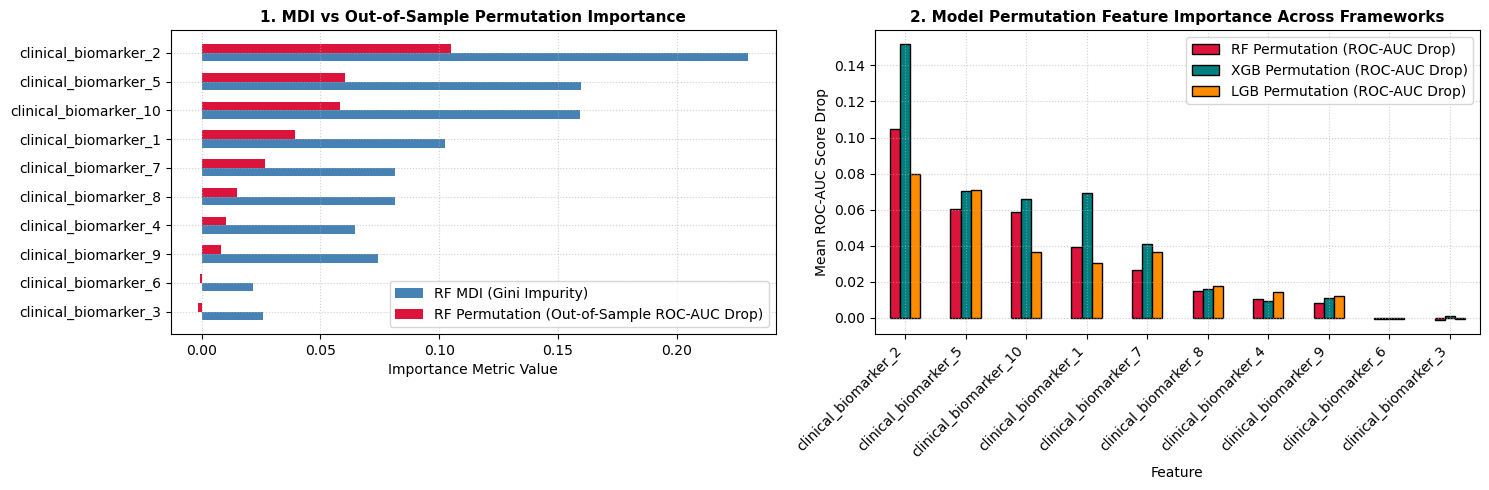

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sorted_idx = df_importance['RF Permutation (ROC-AUC Drop)'].argsort()
y_pos = np.arange(len(feature_cols))

axes[0].barh(y_pos - 0.15, df_importance['RF MDI (Gini)'][sorted_idx], height=0.3, color='steelblue', label='RF MDI (Gini Impurity)')
axes[0].barh(y_pos + 0.15, df_importance['RF Permutation (ROC-AUC Drop)'][sorted_idx], height=0.3, color='crimson', label='RF Permutation (Out-of-Sample ROC-AUC Drop)')
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels(df_importance['Feature'][sorted_idx])
axes[0].set_title("1. MDI vs Out-of-Sample Permutation Importance", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Importance Metric Value")
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].legend(loc='lower right')

df_plot_perm = df_importance.set_index('Feature')[['RF Permutation (ROC-AUC Drop)', 'XGB Permutation (ROC-AUC Drop)', 'LGB Permutation (ROC-AUC Drop)']]
df_plot_perm.plot(kind='bar', ax=axes[1], color=['crimson', 'teal', 'darkorange'], edgecolor='black')
axes[1].set_title("2. Model Permutation Feature Importance Across Frameworks", fontsize=11, fontweight='bold')
axes[1].set_ylabel("Mean ROC-AUC Score Drop")
axes[1].grid(True, linestyle=':', alpha=0.6)
plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()